### House Price Dataset

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
dataset = pd.read_csv("../datasets/house-prices-advanced-regression-techniques/train.csv")

In [3]:
dataset.shape

(1460, 81)

In [4]:
dataset.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


### Feature Engineering

Step - 1 Dropping the irrelevant columns

In [5]:
dataset = dataset.drop(columns= ["Id"])

In [6]:
dataset.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


### Handling Missing data

In [7]:
# Finding the count of missing values


missing_values = dataset.isnull().sum().sort_values(ascending=False)
missing_values = missing_values[missing_values > 0]

In [8]:
missing_values

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageType        81
GarageFinish      81
GarageCond        81
GarageYrBlt       81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtFinType1      37
BsmtCond          37
MasVnrArea         8
Electrical         1
dtype: int64

In [9]:
missing_values_percentage = dataset.isnull().mean().sort_values(ascending = False)
print(missing_values_percentage)

### Percentage of TRUE with total values

PoolQC           0.995205
MiscFeature      0.963014
Alley            0.937671
Fence            0.807534
MasVnrType       0.597260
                   ...   
MoSold           0.000000
YrSold           0.000000
SaleType         0.000000
SaleCondition    0.000000
SalePrice        0.000000
Length: 80, dtype: float64


In [10]:
### Drop Columns which has too many missing values

threshold = 0.65
columns_with_high_missing_values = missing_values_percentage[missing_values_percentage > threshold].index.to_list()
print(columns_with_high_missing_values)


['PoolQC', 'MiscFeature', 'Alley', 'Fence']


In [11]:
dataset_1 = dataset.drop(columns = columns_with_high_missing_values , errors = 'ignore')


In [12]:
dataset_1.shape

(1460, 76)

In [13]:
dataset_1.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,LotShape,LandContour,Utilities,LotConfig,LandSlope,...,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,65.0,8450,Pave,Reg,Lvl,AllPub,Inside,Gtl,...,0,0,0,0,0,2,2008,WD,Normal,208500
1,20,RL,80.0,9600,Pave,Reg,Lvl,AllPub,FR2,Gtl,...,0,0,0,0,0,5,2007,WD,Normal,181500
2,60,RL,68.0,11250,Pave,IR1,Lvl,AllPub,Inside,Gtl,...,0,0,0,0,0,9,2008,WD,Normal,223500
3,70,RL,60.0,9550,Pave,IR1,Lvl,AllPub,Corner,Gtl,...,272,0,0,0,0,2,2006,WD,Abnorml,140000
4,60,RL,84.0,14260,Pave,IR1,Lvl,AllPub,FR2,Gtl,...,0,0,0,0,0,12,2008,WD,Normal,250000


In [14]:
### Filter by importance
# Correlation with Sale_Price

correlation_matrix = dataset_1.select_dtypes(include = [np.number]).corr()
correlation_matrix_with_sales_price = correlation_matrix['SalePrice'].abs()
print(correlation_matrix_with_sales_price)

MSSubClass       0.084284
LotFrontage      0.351799
LotArea          0.263843
OverallQual      0.790982
OverallCond      0.077856
YearBuilt        0.522897
YearRemodAdd     0.507101
MasVnrArea       0.477493
BsmtFinSF1       0.386420
BsmtFinSF2       0.011378
BsmtUnfSF        0.214479
TotalBsmtSF      0.613581
1stFlrSF         0.605852
2ndFlrSF         0.319334
LowQualFinSF     0.025606
GrLivArea        0.708624
BsmtFullBath     0.227122
BsmtHalfBath     0.016844
FullBath         0.560664
HalfBath         0.284108
BedroomAbvGr     0.168213
KitchenAbvGr     0.135907
TotRmsAbvGrd     0.533723
Fireplaces       0.466929
GarageYrBlt      0.486362
GarageCars       0.640409
GarageArea       0.623431
WoodDeckSF       0.324413
OpenPorchSF      0.315856
EnclosedPorch    0.128578
3SsnPorch        0.044584
ScreenPorch      0.111447
PoolArea         0.092404
MiscVal          0.021190
MoSold           0.046432
YrSold           0.028923
SalePrice        1.000000
Name: SalePrice, dtype: float64


In [15]:
low_impacted_threshold = 0.1
columns_to_drop_based_on_correlation = correlation_matrix_with_sales_price[correlation_matrix_with_sales_price < 0.1].index.to_list()
print(columns_to_drop_based_on_correlation)

['MSSubClass', 'OverallCond', 'BsmtFinSF2', 'LowQualFinSF', 'BsmtHalfBath', '3SsnPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold']


In [16]:
dataset_2 = dataset_1.drop(columns= columns_to_drop_based_on_correlation , errors = "ignore")

In [17]:
dataset_2.shape

(1460, 66)

In [18]:
# Removing Multi Colinearity

correlation_matrix = dataset.select_dtypes(include=[np.number]).corr().abs()

In [19]:
correlation_matrix

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
MSSubClass,1.000000,0.386347,0.139781,0.032628,0.059316,0.027850,0.040581,0.022936,0.069836,0.065649,...,0.012579,0.006100,0.012037,0.043825,0.026030,0.008283,0.007683,0.013585,0.021407,0.084284
LotFrontage,0.386347,1.000000,0.426095,0.251646,0.059213,0.123349,0.088866,0.193458,0.233633,0.049900,...,0.088521,0.151972,0.010700,0.070029,0.041383,0.206167,0.003368,0.011200,0.007450,0.351799
LotArea,0.139781,0.426095,1.000000,0.105806,0.005636,0.014228,0.013788,0.104160,0.214103,0.111170,...,0.171698,0.084774,0.018340,0.020423,0.043160,0.077672,0.038068,0.001205,0.014261,0.263843
OverallQual,0.032628,0.251646,0.105806,1.000000,0.091932,0.572323,0.550684,0.411876,0.239666,0.059119,...,0.238923,0.308819,0.113937,0.030371,0.064886,0.065166,0.031406,0.070815,0.027347,0.790982
OverallCond,0.059316,0.059213,0.005636,0.091932,1.000000,0.375983,0.073741,0.128101,0.046231,0.040229,...,0.003334,0.032589,0.070356,0.025504,0.054811,0.001985,0.068777,0.003511,0.043950,0.077856
YearBuilt,0.027850,0.123349,0.014228,0.572323,0.375983,1.000000,0.592855,0.315707,0.249503,0.049107,...,0.224880,0.188686,0.387268,0.031355,0.050364,0.004950,0.034383,0.012398,0.013618,0.522897
YearRemodAdd,0.040581,0.088866,0.013788,0.550684,0.073741,0.592855,1.000000,0.179618,0.128451,0.067759,...,0.205726,0.226298,0.193919,0.045286,0.038740,0.005829,0.010286,0.021490,0.035743,0.507101
MasVnrArea,0.022936,0.193458,0.104160,0.411876,0.128101,0.315707,0.179618,1.000000,0.264736,0.072319,...,0.159718,0.125703,0.110204,0.018796,0.061466,0.011723,0.029815,0.005965,0.008201,0.477493
BsmtFinSF1,0.069836,0.233633,0.214103,0.239666,0.046231,0.249503,0.128451,0.264736,1.000000,0.050117,...,0.204306,0.111761,0.102303,0.026451,0.062021,0.140491,0.003571,0.015727,0.014359,0.386420
BsmtFinSF2,0.065649,0.049900,0.111170,0.059119,0.040229,0.049107,0.067759,0.072319,0.050117,1.000000,...,0.067898,0.003093,0.036543,0.029993,0.088871,0.041709,0.004940,0.015211,0.031706,0.011378


In [20]:
np.triu(np.ones(correlation_matrix.shape) , k = 1).astype(bool)

# K values detremines the diagonal 

array([[False,  True,  True, ...,  True,  True,  True],
       [False, False,  True, ...,  True,  True,  True],
       [False, False, False, ...,  True,  True,  True],
       ...,
       [False, False, False, ..., False,  True,  True],
       [False, False, False, ..., False, False,  True],
       [False, False, False, ..., False, False, False]], shape=(37, 37))

In [21]:
upper = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape), k = 1).astype(bool))
upper

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
MSSubClass,NaN,0.386347,0.139781,0.032628,0.059316,0.027850,0.040581,0.022936,0.069836,0.065649,...,0.012579,0.006100,0.012037,0.043825,0.026030,0.008283,0.007683,0.013585,0.021407,0.084284
LotFrontage,NaN,NaN,0.426095,0.251646,0.059213,0.123349,0.088866,0.193458,0.233633,0.049900,...,0.088521,0.151972,0.010700,0.070029,0.041383,0.206167,0.003368,0.011200,0.007450,0.351799
LotArea,NaN,NaN,NaN,0.105806,0.005636,0.014228,0.013788,0.104160,0.214103,0.111170,...,0.171698,0.084774,0.018340,0.020423,0.043160,0.077672,0.038068,0.001205,0.014261,0.263843
OverallQual,NaN,NaN,NaN,NaN,0.091932,0.572323,0.550684,0.411876,0.239666,0.059119,...,0.238923,0.308819,0.113937,0.030371,0.064886,0.065166,0.031406,0.070815,0.027347,0.790982
OverallCond,NaN,NaN,NaN,NaN,NaN,0.375983,0.073741,0.128101,0.046231,0.040229,...,0.003334,0.032589,0.070356,0.025504,0.054811,0.001985,0.068777,0.003511,0.043950,0.077856
YearBuilt,NaN,NaN,NaN,NaN,NaN,NaN,0.592855,0.315707,0.249503,0.049107,...,0.224880,0.188686,0.387268,0.031355,0.050364,0.004950,0.034383,0.012398,0.013618,0.522897
YearRemodAdd,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.179618,0.128451,0.067759,...,0.205726,0.226298,0.193919,0.045286,0.038740,0.005829,0.010286,0.021490,0.035743,0.507101
MasVnrArea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.264736,0.072319,...,0.159718,0.125703,0.110204,0.018796,0.061466,0.011723,0.029815,0.005965,0.008201,0.477493
BsmtFinSF1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.050117,...,0.204306,0.111761,0.102303,0.026451,0.062021,0.140491,0.003571,0.015727,0.014359,0.386420
BsmtFinSF2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.067898,0.003093,0.036543,0.029993,0.088871,0.041709,0.004940,0.015211,0.031706,0.011378


In [22]:
for column in upper.columns:
  print(column)

MSSubClass
LotFrontage
LotArea
OverallQual
OverallCond
YearBuilt
YearRemodAdd
MasVnrArea
BsmtFinSF1
BsmtFinSF2
BsmtUnfSF
TotalBsmtSF
1stFlrSF
2ndFlrSF
LowQualFinSF
GrLivArea
BsmtFullBath
BsmtHalfBath
FullBath
HalfBath
BedroomAbvGr
KitchenAbvGr
TotRmsAbvGrd
Fireplaces
GarageYrBlt
GarageCars
GarageArea
WoodDeckSF
OpenPorchSF
EnclosedPorch
3SsnPorch
ScreenPorch
PoolArea
MiscVal
MoSold
YrSold
SalePrice


In [23]:
redundant_cols = [column for column in upper.columns if any (upper[column] > 0.8)]
print(redundant_cols)

['1stFlrSF', 'TotRmsAbvGrd', 'GarageYrBlt', 'GarageArea']


In [24]:
dataset_3 = dataset_2.drop(columns=redundant_cols , errors = "ignore")

In [25]:
dataset_3.shape

(1460, 62)

In [26]:
dataset_3.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 62 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSZoning       1460 non-null   str    
 1   LotFrontage    1201 non-null   float64
 2   LotArea        1460 non-null   int64  
 3   Street         1460 non-null   str    
 4   LotShape       1460 non-null   str    
 5   LandContour    1460 non-null   str    
 6   Utilities      1460 non-null   str    
 7   LotConfig      1460 non-null   str    
 8   LandSlope      1460 non-null   str    
 9   Neighborhood   1460 non-null   str    
 10  Condition1     1460 non-null   str    
 11  Condition2     1460 non-null   str    
 12  BldgType       1460 non-null   str    
 13  HouseStyle     1460 non-null   str    
 14  OverallQual    1460 non-null   int64  
 15  YearBuilt      1460 non-null   int64  
 16  YearRemodAdd   1460 non-null   int64  
 17  RoofStyle      1460 non-null   str    
 18  RoofMatl       1460

In [27]:
missing_values = dataset_3.isnull().sum()
missing_values = missing_values[missing_values > 0].sort_values(ascending = False)

In [28]:
missing_values

MasVnrType      872
FireplaceQu     690
LotFrontage     259
GarageType       81
GarageQual       81
GarageFinish     81
GarageCond       81
BsmtFinType2     38
BsmtExposure     38
BsmtQual         37
BsmtFinType1     37
BsmtCond         37
MasVnrArea        8
Electrical        1
dtype: int64

In [29]:
temp_df = dataset_3.dropna()

In [30]:
temp_df.shape

(299, 62)

In [31]:
# Mean Imputation
dataset_3['LotFrontage']

0       65.0
1       80.0
2       68.0
3       60.0
4       84.0
        ... 
1455    62.0
1456    85.0
1457    66.0
1458    68.0
1459    75.0
Name: LotFrontage, Length: 1460, dtype: float64

In [32]:
dataset_mean = dataset_3.copy()

In [33]:
dataset_mean.fillna({"LotFrontage" : dataset_mean['LotFrontage'].mean()} , inplace = True)

,MSZoning,LotFrontage,LotArea,Street,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,...,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,ScreenPorch,SaleType,SaleCondition,SalePrice
0,RL,65.0,8450,Pave,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,...,TA,TA,Y,0,61,0,0,WD,Normal,208500
1,RL,80.0,9600,Pave,Reg,Lvl,AllPub,FR2,Gtl,Veenker,...,TA,TA,Y,298,0,0,0,WD,Normal,181500
2,RL,68.0,11250,Pave,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,...,TA,TA,Y,0,42,0,0,WD,Normal,223500
3,RL,60.0,9550,Pave,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,...,TA,TA,Y,0,35,272,0,WD,Abnorml,140000
4,RL,84.0,14260,Pave,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,...,TA,TA,Y,192,84,0,0,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,RL,62.0,7917,Pave,Reg,Lvl,AllPub,Inside,Gtl,Gilbert,...,TA,TA,Y,0,40,0,0,WD,Normal,175000
1456,RL,85.0,13175,Pave,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,...,TA,TA,Y,349,0,0,0,WD,Normal,210000
1457,RL,66.0,9042,Pave,Reg,Lvl,AllPub,Inside,Gtl,Crawfor,...,TA,TA,Y,0,60,0,0,WD,Normal,266500
1458,RL,68.0,9717,Pave,Reg,Lvl,AllPub,Inside,Gtl,NAmes,...,TA,TA,Y,366,0,112,0,WD,Normal,142125


In [34]:
missing_values = dataset_mean.isnull().sum()
missing_values = missing_values[missing_values > 0].sort_values(ascending = False)

In [35]:
missing_values

MasVnrType      872
FireplaceQu     690
GarageType       81
GarageQual       81
GarageFinish     81
GarageCond       81
BsmtFinType2     38
BsmtExposure     38
BsmtQual         37
BsmtFinType1     37
BsmtCond         37
MasVnrArea        8
Electrical        1
dtype: int64

In [36]:
dataset_median = dataset_3.copy()
dataset_median.fillna({"LotFrontage" : dataset_median['LotFrontage'].median()} , inplace = True)

,MSZoning,LotFrontage,LotArea,Street,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,...,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,ScreenPorch,SaleType,SaleCondition,SalePrice
0,RL,65.0,8450,Pave,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,...,TA,TA,Y,0,61,0,0,WD,Normal,208500
1,RL,80.0,9600,Pave,Reg,Lvl,AllPub,FR2,Gtl,Veenker,...,TA,TA,Y,298,0,0,0,WD,Normal,181500
2,RL,68.0,11250,Pave,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,...,TA,TA,Y,0,42,0,0,WD,Normal,223500
3,RL,60.0,9550,Pave,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,...,TA,TA,Y,0,35,272,0,WD,Abnorml,140000
4,RL,84.0,14260,Pave,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,...,TA,TA,Y,192,84,0,0,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,RL,62.0,7917,Pave,Reg,Lvl,AllPub,Inside,Gtl,Gilbert,...,TA,TA,Y,0,40,0,0,WD,Normal,175000
1456,RL,85.0,13175,Pave,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,...,TA,TA,Y,349,0,0,0,WD,Normal,210000
1457,RL,66.0,9042,Pave,Reg,Lvl,AllPub,Inside,Gtl,Crawfor,...,TA,TA,Y,0,60,0,0,WD,Normal,266500
1458,RL,68.0,9717,Pave,Reg,Lvl,AllPub,Inside,Gtl,NAmes,...,TA,TA,Y,366,0,112,0,WD,Normal,142125


In [37]:
missing_values = dataset_mean.isnull().sum()
missing_values = missing_values[missing_values > 0].sort_values(ascending = False)
print(missing_values)

MasVnrType      872
FireplaceQu     690
GarageType       81
GarageQual       81
GarageFinish     81
GarageCond       81
BsmtFinType2     38
BsmtExposure     38
BsmtQual         37
BsmtFinType1     37
BsmtCond         37
MasVnrArea        8
Electrical        1
dtype: int64


In [38]:
dataset_3.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 62 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSZoning       1460 non-null   str    
 1   LotFrontage    1201 non-null   float64
 2   LotArea        1460 non-null   int64  
 3   Street         1460 non-null   str    
 4   LotShape       1460 non-null   str    
 5   LandContour    1460 non-null   str    
 6   Utilities      1460 non-null   str    
 7   LotConfig      1460 non-null   str    
 8   LandSlope      1460 non-null   str    
 9   Neighborhood   1460 non-null   str    
 10  Condition1     1460 non-null   str    
 11  Condition2     1460 non-null   str    
 12  BldgType       1460 non-null   str    
 13  HouseStyle     1460 non-null   str    
 14  OverallQual    1460 non-null   int64  
 15  YearBuilt      1460 non-null   int64  
 16  YearRemodAdd   1460 non-null   int64  
 17  RoofStyle      1460 non-null   str    
 18  RoofMatl       1460

In [39]:
dataset_mode = dataset_3.copy()

In [40]:
dataset_mode['GarageType'].unique()

<ArrowStringArray>
['Attchd', 'Detchd', 'BuiltIn', 'CarPort', nan, 'Basment', '2Types']
Length: 7, dtype: str

In [41]:
dataset_mode['GarageType'].isnull().sum() # null values

np.int64(81)

In [42]:
dataset_mode["GarageType"].mode()[0]

'Attchd'

In [43]:
dataset_mode.fillna({'GarageType' : dataset_mode['GarageType'].mode()[0]} , inplace = True)

,MSZoning,LotFrontage,LotArea,Street,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,...,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,ScreenPorch,SaleType,SaleCondition,SalePrice
0,RL,65.0,8450,Pave,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,...,TA,TA,Y,0,61,0,0,WD,Normal,208500
1,RL,80.0,9600,Pave,Reg,Lvl,AllPub,FR2,Gtl,Veenker,...,TA,TA,Y,298,0,0,0,WD,Normal,181500
2,RL,68.0,11250,Pave,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,...,TA,TA,Y,0,42,0,0,WD,Normal,223500
3,RL,60.0,9550,Pave,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,...,TA,TA,Y,0,35,272,0,WD,Abnorml,140000
4,RL,84.0,14260,Pave,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,...,TA,TA,Y,192,84,0,0,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,RL,62.0,7917,Pave,Reg,Lvl,AllPub,Inside,Gtl,Gilbert,...,TA,TA,Y,0,40,0,0,WD,Normal,175000
1456,RL,85.0,13175,Pave,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,...,TA,TA,Y,349,0,0,0,WD,Normal,210000
1457,RL,66.0,9042,Pave,Reg,Lvl,AllPub,Inside,Gtl,Crawfor,...,TA,TA,Y,0,60,0,0,WD,Normal,266500
1458,RL,68.0,9717,Pave,Reg,Lvl,AllPub,Inside,Gtl,NAmes,...,TA,TA,Y,366,0,112,0,WD,Normal,142125


In [44]:
dataset_mode['GarageType'].isnull().sum()

np.int64(0)

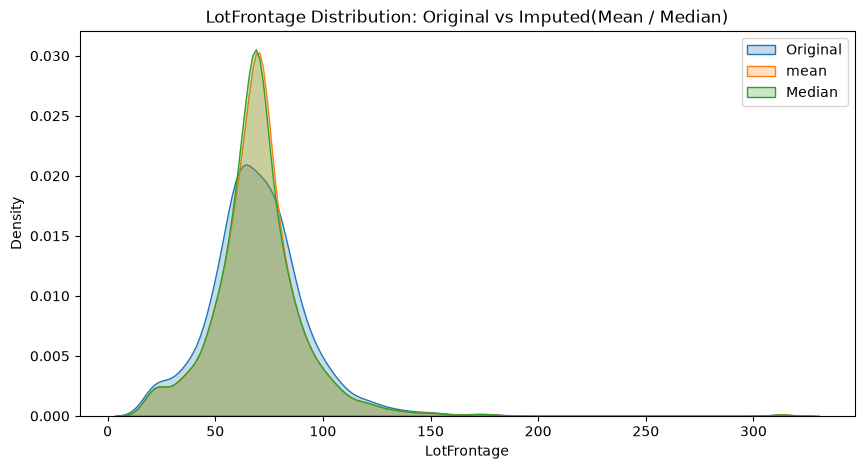

In [45]:
# Compare before and after imputation

plt.figure(figsize=(10, 5))
sns.kdeplot(dataset_3["LotFrontage"] , label = "Original" , fill = True)
sns.kdeplot(dataset_mean['LotFrontage'] , label = "mean" , fill=True)
sns.kdeplot(dataset_median['LotFrontage'] , label = "Median" , fill=True)
plt.legend()
plt.title("LotFrontage Distribution: Original vs Imputed(Mean / Median)")
plt.show()

In [46]:

# pip install scikit-learn

In [47]:
from sklearn.impute import KNNImputer

In [48]:
knn_imputer = KNNImputer(n_neighbors = 5)


In [49]:
dataset_knn = dataset_3.copy()

In [50]:
missing_values = dataset_knn.isnull().sum()
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)
print(missing_values)

MasVnrType      872
FireplaceQu     690
LotFrontage     259
GarageType       81
GarageQual       81
GarageFinish     81
GarageCond       81
BsmtFinType2     38
BsmtExposure     38
BsmtQual         37
BsmtFinType1     37
BsmtCond         37
MasVnrArea        8
Electrical        1
dtype: int64


In [51]:
numerical_columns = dataset_knn.select_dtypes(include=[np.number]).columns
numerical_columns

Index(['LotFrontage', 'LotArea', 'OverallQual', 'YearBuilt', 'YearRemodAdd',
       'MasVnrArea', 'BsmtFinSF1', 'BsmtUnfSF', 'TotalBsmtSF', '2ndFlrSF',
       'GrLivArea', 'BsmtFullBath', 'FullBath', 'HalfBath', 'BedroomAbvGr',
       'KitchenAbvGr', 'Fireplaces', 'GarageCars', 'WoodDeckSF', 'OpenPorchSF',
       'EnclosedPorch', 'ScreenPorch', 'SalePrice'],
      dtype='str')

In [52]:
dataset_knn[numerical_columns] = knn_imputer.fit_transform(dataset_knn[numerical_columns])

In [53]:
missing_values = dataset_knn.isnull().sum()
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)
print(missing_values)

MasVnrType      872
FireplaceQu     690
GarageQual       81
GarageFinish     81
GarageCond       81
GarageType       81
BsmtExposure     38
BsmtFinType2     38
BsmtCond         37
BsmtQual         37
BsmtFinType1     37
Electrical        1
dtype: int64


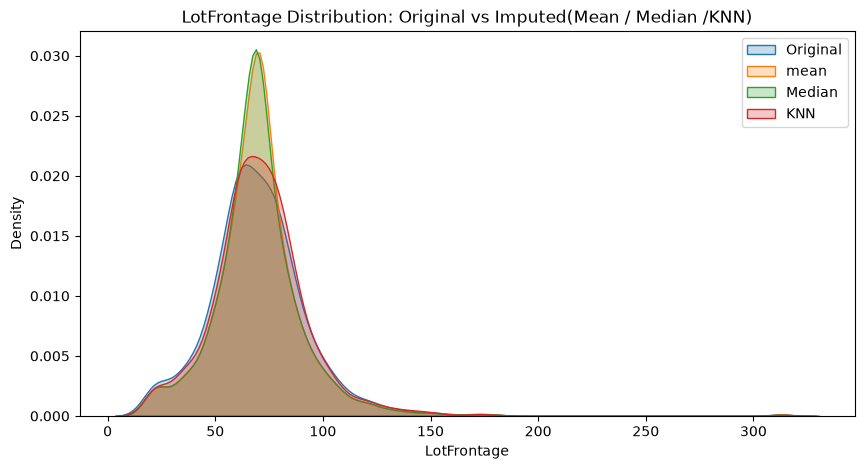

In [54]:
# Compare before and after imputation

plt.figure(figsize=(10, 5))
sns.kdeplot(dataset_3["LotFrontage"] , label = "Original" , fill = True)
sns.kdeplot(dataset_mean['LotFrontage'] , label = "mean" , fill=True)
sns.kdeplot(dataset_median['LotFrontage'] , label = "Median" , fill=True)
sns.kdeplot(dataset_knn['LotFrontage'] , label = "KNN" , fill=True)
plt.legend()
plt.title("LotFrontage Distribution: Original vs Imputed(Mean / Median /KNN)")
plt.show()

In [55]:
# Regression Imputation

from sklearn.linear_model import LinearRegression

In [56]:
dataset_regression = dataset_3.copy()

In [57]:
train_data = dataset_regression.dropna(subset=["LotFrontage"])
test_data = dataset_regression[dataset_regression['LotFrontage'].isnull()]

In [58]:
train_data.isnull().sum()

MSZoning         0
LotFrontage      0
LotArea          0
Street           0
LotShape         0
                ..
EnclosedPorch    0
ScreenPorch      0
SaleType         0
SaleCondition    0
SalePrice        0
Length: 62, dtype: int64

In [59]:
correlation = dataset_regression.select_dtypes(include=[np.number]).corr()['LotFrontage'].abs()
correlation = correlation.sort_values(ascending=False)
print(correlation)

LotFrontage      1.000000
LotArea          0.426095
GrLivArea        0.402797
TotalBsmtSF      0.392075
SalePrice        0.351799
GarageCars       0.285691
Fireplaces       0.266639
BedroomAbvGr     0.263170
OverallQual      0.251646
BsmtFinSF1       0.233633
FullBath         0.198769
MasVnrArea       0.193458
OpenPorchSF      0.151972
BsmtUnfSF        0.132644
YearBuilt        0.123349
BsmtFullBath     0.100949
YearRemodAdd     0.088866
WoodDeckSF       0.088521
2ndFlrSF         0.080177
HalfBath         0.053532
ScreenPorch      0.041383
EnclosedPorch    0.010700
KitchenAbvGr     0.006069
Name: LotFrontage, dtype: float64


In [60]:
train_data[['LotArea','GrLivArea','TotalBsmtSF','SalePrice']]

,LotArea,GrLivArea,TotalBsmtSF,SalePrice
0,8450,1710,856,208500
1,9600,1262,1262,181500
2,11250,1786,920,223500
3,9550,1717,756,140000
4,14260,2198,1145,250000
...,...,...,...,...
1455,7917,1647,953,175000
1456,13175,2073,1542,210000
1457,9042,2340,1152,266500
1458,9717,1078,1078,142125


In [61]:
train_data[['LotArea','GrLivArea','TotalBsmtSF','SalePrice']].isnull().sum()

LotArea        0
GrLivArea      0
TotalBsmtSF    0
SalePrice      0
dtype: int64

In [62]:
X_train = train_data[['LotArea','GrLivArea','TotalBsmtSF','SalePrice']]
y_train = train_data['LotFrontage']

In [63]:
regression = LinearRegression()


In [64]:
regression.fit(X_train , y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 0. , 0.01, 0.01,-0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['LotArea','GrLivArea','TotalBsmtSF','SalePrice']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,34.56
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [65]:
regression.coef_

array([ 9.15076023e-04,  1.08265388e-02,  1.14488603e-02, -1.16246644e-05])

In [66]:
test_data[['LotArea','GrLivArea','TotalBsmtSF','SalePrice']].isnull().sum()

LotArea        0
GrLivArea      0
TotalBsmtSF    0
SalePrice      0
dtype: int64

In [67]:
dataset_regression.loc[dataset_regression["LotFrontage"].isnull() , "LotFrontage"] =  regression.predict(test_data[['LotArea','GrLivArea','TotalBsmtSF','SalePrice']])

In [68]:
dataset_regression['LotFrontage'].isnull().sum()

np.int64(0)

In [69]:
def compare_imputation(df_before, df_after, column_name):
    missing_indices = {column_name : df_before[df_before[column_name].isnull()].index.to_list() for column_name in df_before.columns if df_before[column_name].isnull().any()}

    if column_name not in missing_indices:
        print(f"No missing values were found in column '{column_name}'")
        return

    idx_list = missing_indices[column_name]

    comparison = pd.DataFrame({
        "Before" : df_before.loc[idx_list,column_name], 
        "After" : df_after.loc[idx_list,column_name], 
    })

    print(f"Changes in column : {column_name}")
    return comparison

In [70]:
compare_imputation(dataset_3, dataset_regression, "LotFrontage").head(10)

Changes in column : LotFrontage


,Before,After
7,NaN,77.032454
12,NaN,65.063631
14,NaN,70.634346
16,NaN,65.474508
24,NaN,63.923155
31,NaN,67.992169
42,NaN,60.469862
43,NaN,62.354624
50,NaN,70.194744
64,NaN,74.705562


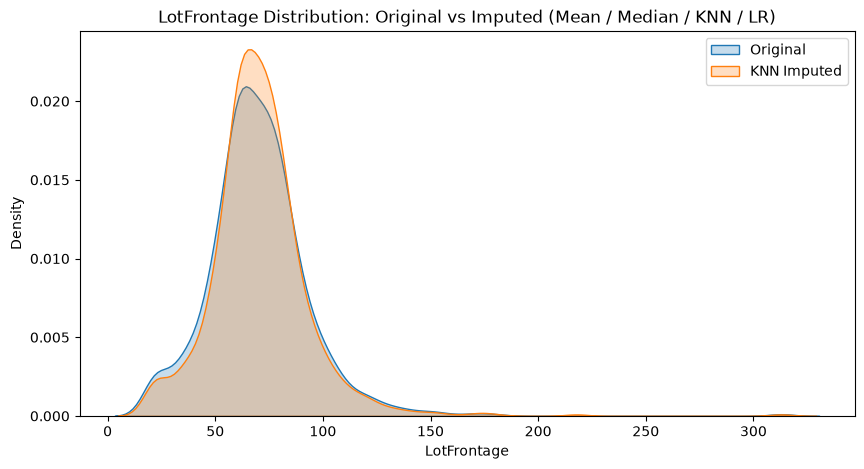

In [71]:
plt.figure(figsize=(10,5))
# kdeplot --> plot that shows pdf
sns.kdeplot(dataset_3["LotFrontage"], label="Original", fill=True)
sns.kdeplot(dataset_regression["LotFrontage"], label="KNN Imputed", fill=True)
# sns.kdeplot(df_reg["LotFrontage"], label="LinearRegression Imputed", fill=True)
plt.legend()
plt.title("LotFrontage Distribution: Original vs Imputed (Mean / Median / KNN / LR)")
plt.show()

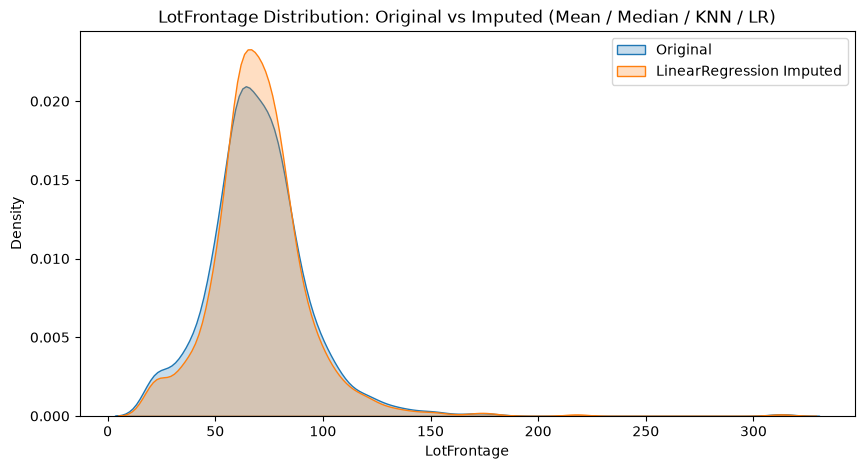

In [72]:
plt.figure(figsize=(10,5))
# kdeplot --> plot that shows pdf
sns.kdeplot(dataset_3["LotFrontage"], label="Original", fill=True)
# sns.kdeplot(df_knn["LotFrontage"], label="KNN Imputed", fill=True)
sns.kdeplot(dataset_regression["LotFrontage"], label="LinearRegression Imputed", fill=True)
plt.legend()
plt.title("LotFrontage Distribution: Original vs Imputed (Mean / Median / KNN / LR)")
plt.show()

In [73]:
# Filling missing values using Interative Imputer

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import LinearRegression

In [74]:
cols_to_use = ["LotFrontage" , "LotArea" , "OverallQual" , "GrLivArea"]

In [75]:
dataset_subset = dataset_3[cols_to_use].copy()

In [76]:
itr_imputer = IterativeImputer(estimator=LinearRegression() , max_iter=10 , random_state=10)

In [77]:
imputed_values = itr_imputer.fit_transform(dataset_subset)

In [78]:
print(imputed_values)

[[6.500e+01 8.450e+03 7.000e+00 1.710e+03]
 [8.000e+01 9.600e+03 6.000e+00 1.262e+03]
 [6.800e+01 1.125e+04 7.000e+00 1.786e+03]
 ...
 [6.600e+01 9.042e+03 7.000e+00 2.340e+03]
 [6.800e+01 9.717e+03 5.000e+00 1.078e+03]
 [7.500e+01 9.937e+03 5.000e+00 1.256e+03]]


In [79]:
dataset_subset[cols_to_use] = imputed_values

In [80]:
dataset_subset.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   LotFrontage  1460 non-null   float64
 1   LotArea      1460 non-null   float64
 2   OverallQual  1460 non-null   float64
 3   GrLivArea    1460 non-null   float64
dtypes: float64(4)
memory usage: 45.8 KB


### Handling Outliers

In [81]:
dataset_3.head()

,MSZoning,LotFrontage,LotArea,Street,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,...,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,ScreenPorch,SaleType,SaleCondition,SalePrice
0,RL,65.0,8450,Pave,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,...,TA,TA,Y,0,61,0,0,WD,Normal,208500
1,RL,80.0,9600,Pave,Reg,Lvl,AllPub,FR2,Gtl,Veenker,...,TA,TA,Y,298,0,0,0,WD,Normal,181500
2,RL,68.0,11250,Pave,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,...,TA,TA,Y,0,42,0,0,WD,Normal,223500
3,RL,60.0,9550,Pave,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,...,TA,TA,Y,0,35,272,0,WD,Abnorml,140000
4,RL,84.0,14260,Pave,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,...,TA,TA,Y,192,84,0,0,WD,Normal,250000


In [82]:
dataset_3.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 62 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSZoning       1460 non-null   str    
 1   LotFrontage    1201 non-null   float64
 2   LotArea        1460 non-null   int64  
 3   Street         1460 non-null   str    
 4   LotShape       1460 non-null   str    
 5   LandContour    1460 non-null   str    
 6   Utilities      1460 non-null   str    
 7   LotConfig      1460 non-null   str    
 8   LandSlope      1460 non-null   str    
 9   Neighborhood   1460 non-null   str    
 10  Condition1     1460 non-null   str    
 11  Condition2     1460 non-null   str    
 12  BldgType       1460 non-null   str    
 13  HouseStyle     1460 non-null   str    
 14  OverallQual    1460 non-null   int64  
 15  YearBuilt      1460 non-null   int64  
 16  YearRemodAdd   1460 non-null   int64  
 17  RoofStyle      1460 non-null   str    
 18  RoofMatl       1460

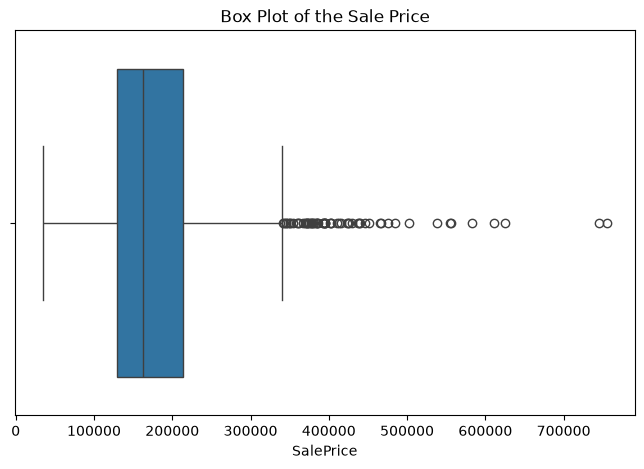

In [83]:
# Visualizing the outliers

plt.figure(figsize=(8 , 5))
sns.boxplot(x = dataset_3['SalePrice'])
plt.title("Box Plot of the Sale Price")
plt.show()

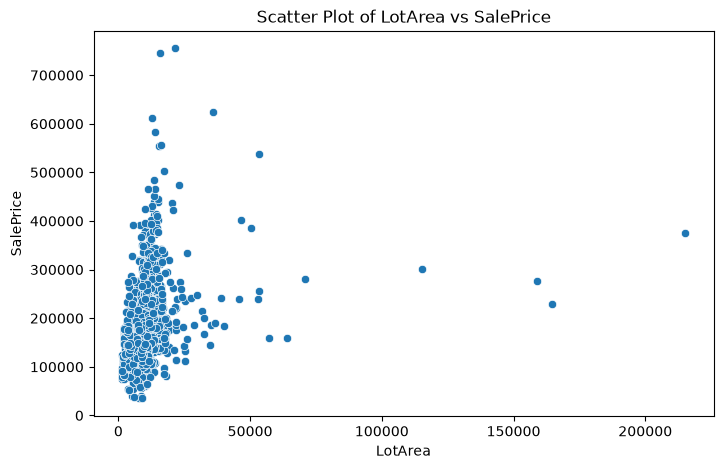

In [84]:
# Scatter Plot of LotArea vs SalePrice

plt.figure(figsize=(8 , 5))
sns.scatterplot( x = dataset_3['LotArea'] , y = dataset_3['SalePrice'] , marker='o')
plt.title("Scatter Plot of LotArea vs SalePrice")
plt.show()

In [85]:
# Finding the outliers using IQR (Inter Quartile Range)

# outliers = values outside [Q1 - 1.5 * IQR , Q3 + 1.5 * IQR]

In [86]:
def detect_outliers(data , column):
  q1 = data[column].quantile(0.25)
  q3 = data[column].quantile(0.75)
  iqr = q3 - q1
  lower_fence = q1 - (1.5 * iqr)
  upper_fence = q3 + (1.5 * iqr)
  outliers = data[(data[column] < lower_fence) | (data[column] > upper_fence)]
  return outliers[[column]]


In [87]:
outliers_saleprice = detect_outliers(dataset_3 , "SalePrice")

In [88]:
print(f"Number of Outliers in SalePrice = {len(outliers_saleprice)}")

Number of Outliers in SalePrice = 61


In [89]:
outliers_saleprice.head()

,SalePrice
11,345000
53,385000
58,438780
112,383970
151,372402


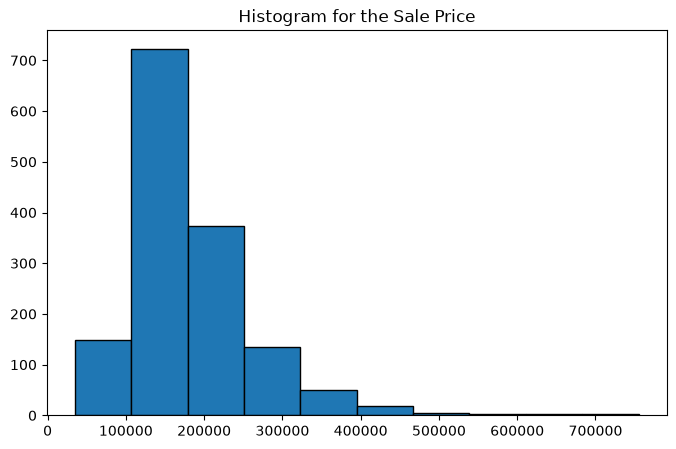

In [90]:
# how to check if data is normally distributed or not

plt.figure(figsize=(8, 5))
plt.hist(dataset_3['SalePrice'] , bins = 10 , edgecolor = 'black')
plt.title("Histogram for the Sale Price")
plt.show()

In [91]:
import scipy.stats as stats

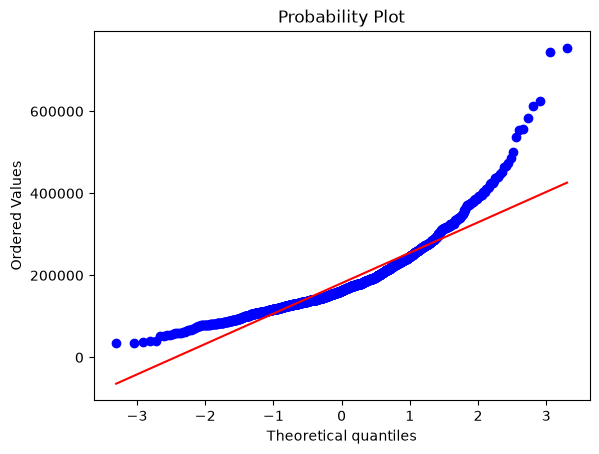

In [92]:
stats.probplot(dataset_3['SalePrice'] , dist ='norm' , plot=plt)
plt.show()

In [93]:
# Shapiro Wilk Test
l = 0.05
stat , p = stats.shapiro(dataset_3['SalePrice'])


In [94]:
stat

np.float64(0.869671467019189)

In [95]:
p

np.float64(3.206141550572777e-33)

In [96]:
if p > l:
  print("Data looks Normal")
else:
  print("Data does not looks normal")

Data does not looks normal


In [97]:
from scipy.stats import zscore

In [98]:
dataset_3["SalePrice_Z"] = zscore(dataset_3['SalePrice'])
outliers_z = dataset_3[dataset_3["SalePrice_Z"].abs() > 3]

In [99]:
print(f"Number of outliers : {len(outliers_z)}")
outliers_z[["SalePrice", "SalePrice_Z"]].head()

Number of outliers : 22


,SalePrice,SalePrice_Z
58,438780,3.246967
178,501837,4.040982
185,475000,3.703050
349,437154,3.226492
389,426000,3.086040


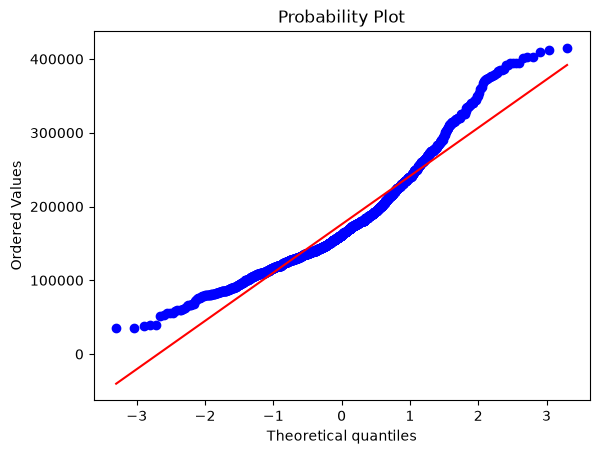

In [100]:
# QQ Plot with out Outliers for Sale Price

without_outliers_z = dataset_3[dataset_3['SalePrice_Z'].abs() < 3]

stats.probplot(without_outliers_z['SalePrice'] , dist ='norm' , plot=plt)
plt.show()

In [101]:
# Modified z-score

from scipy.stats import median_abs_deviation

In [102]:
constant_value = 0.6745
median = dataset_3['SalePrice'].median()
mad = median_abs_deviation(dataset_3['SalePrice'])
dataset_3['SalePrice_Z_mod'] = (constant_value * (dataset_3['SalePrice'] - median)) / (mad)

In [103]:
dataset_3.head()

,MSZoning,LotFrontage,LotArea,Street,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,...,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,ScreenPorch,SaleType,SaleCondition,SalePrice,SalePrice_Z,SalePrice_Z_mod
0,RL,65.0,8450,Pave,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,...,Y,0,61,0,0,WD,Normal,208500,0.347273,0.807625
1,RL,80.0,9600,Pave,Reg,Lvl,AllPub,FR2,Gtl,Veenker,...,Y,298,0,0,0,WD,Normal,181500,0.007288,0.328375
2,RL,68.0,11250,Pave,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,...,Y,0,42,0,0,WD,Normal,223500,0.536154,1.073875
3,RL,60.0,9550,Pave,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,...,Y,0,35,272,0,WD,Abnorml,140000,-0.515281,-0.408250
4,RL,84.0,14260,Pave,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,...,Y,192,84,0,0,WD,Normal,250000,0.869843,1.544250


In [104]:
outliers_z_mod = dataset_3[dataset_3['SalePrice_Z_mod'].abs() > 3.5]
print(f"Number of outlier using (Z-score Modified) : {len(outliers_z_mod)}")
outliers_z_mod[["SalePrice", "SalePrice_Z" , "SalePrice_Z_mod"]].head()

Number of outlier using (Z-score Modified) : 51


,SalePrice,SalePrice_Z,SalePrice_Z_mod
53,385000,2.569767,3.940500
58,438780,3.246967,4.895095
112,383970,2.556797,3.922217
151,372402,2.411133,3.716886
161,412500,2.916048,4.428625


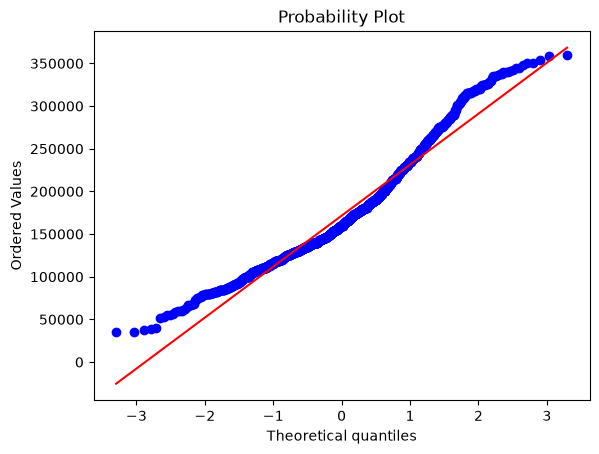

In [105]:
# QQ Plot with out Outliers for Sale Price

without_outliers_z_mod = dataset_3[dataset_3['SalePrice_Z_mod'].abs() <= 3.5]

stats.probplot(without_outliers_z_mod['SalePrice'] , dist ='norm' , plot=plt)
plt.show()

In [106]:
#pip install feature_engine

In [107]:
# Winsorization (Capping Extreme Values)
# Instead of deleting outliers, we cap them to a limit.


In [108]:
from feature_engine.outliers import Winsorizer

In [109]:
winsor = Winsorizer(capping_method='quantiles', fold=0.05 , tail="both" , variables=['SalePrice'])
dataset_3_winsor = winsor.fit_transform(dataset_3)

In [110]:
# Manual Caluculation of 5th and 95th percentile

percentile_5 = dataset_3['SalePrice'].quantile(0.05)
percentile_95 = dataset_3['SalePrice'].quantile(0.95)

print(f"Fifth Percentile of Sale Price : {percentile_5}")
print(f"Ninty Fifth Percentile of Sale Price : {percentile_95}")


Fifth Percentile of Sale Price : 88000.0
Ninty Fifth Percentile of Sale Price : 326099.9999999999


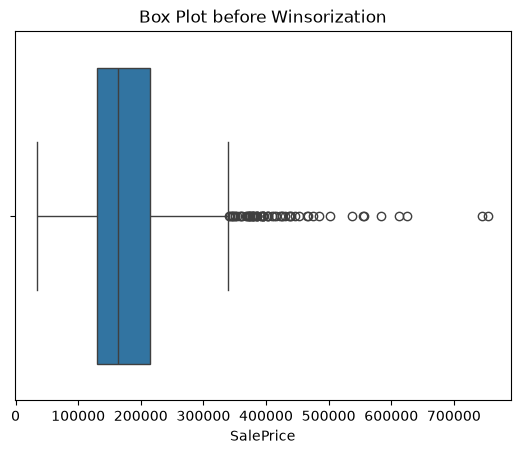

In [111]:
sns.boxplot(x = dataset_3['SalePrice'])
plt.title("Box Plot before Winsorization")
plt.show()

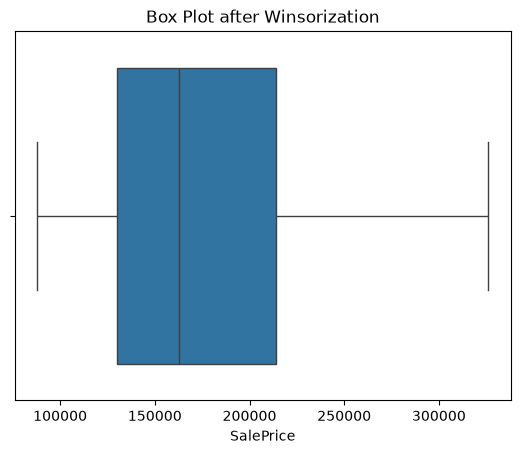

In [112]:
sns.boxplot(x = dataset_3_winsor['SalePrice'])
plt.title("Box Plot after Winsorization")
plt.show()

In [113]:
dataset_3_winsor.shape

(1460, 64)

In [114]:
dataset_3.shape

(1460, 64)

In [115]:
def compare_outliers(original_df, modified_df, column):
  plt.figure(figsize=(12 , 5))
  plt.subplot(1, 2, 1)
  sns.boxplot(x = original_df[column])
  plt.title(f"{column} - Before")

  plt.subplot(1, 2, 2)
  sns.boxplot(x = modified_df[column])
  plt.title(f"{column} - After")

  plt.show()

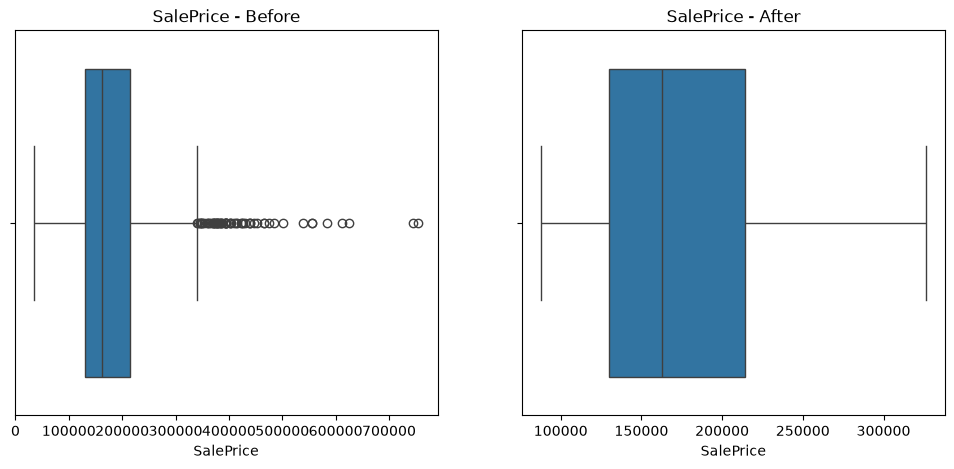

In [116]:
compare_outliers(dataset_3 , dataset_3_winsor , "SalePrice")

### Feature Scaling

In [118]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, PowerTransformer

In [119]:
def summary_statstics(series):
  return {
    "Mean" : series.mean(),
    "Standard Deviation" : series.std(),
    "Skewness" : series.skew()
  }

In [132]:
def compare_distribution(original, transformed , title):
  fig, axes = plt.subplots(1,2, figsize = (12, 8))
  sns.histplot(original , bins = 30 , kde=True , ax = axes[0])
  axes[0].set_title(f"{title} - Before")
  sns.histplot(transformed , bins = 30 , kde=True , ax = axes[1])
  axes[1].set_title(f"{title} - Transformed")

In [133]:
# Standar Scaling

column = 'LotFrontage'
scaler = StandardScaler()
lot_scaled = scaler.fit_transform(dataset_3[[column]])
print("Before : " , summary_statstics(dataset_3[column].dropna()))

Before :  {'Mean': np.float64(70.04995836802665), 'Standard Deviation': np.float64(24.284751774483208), 'Skewness': np.float64(2.1635691423248837)}


In [134]:
lot_scaled

array([[-0.20803433],
       [ 0.40989452],
       [-0.08444856],
       ...,
       [-0.16683907],
       [-0.08444856],
       [ 0.20391824]], shape=(1460, 1))

In [135]:
lot_scaled.flatten()

array([-0.20803433,  0.40989452, -0.08444856, ..., -0.16683907,
       -0.08444856,  0.20391824], shape=(1460,))

In [136]:
print("After : " , summary_statstics(pd.Series(lot_scaled.flatten())))

After :  {'Mean': np.float64(-2.677107310003708e-16), 'Standard Deviation': np.float64(1.0004165798972613), 'Skewness': np.float64(2.1635691423248846)}


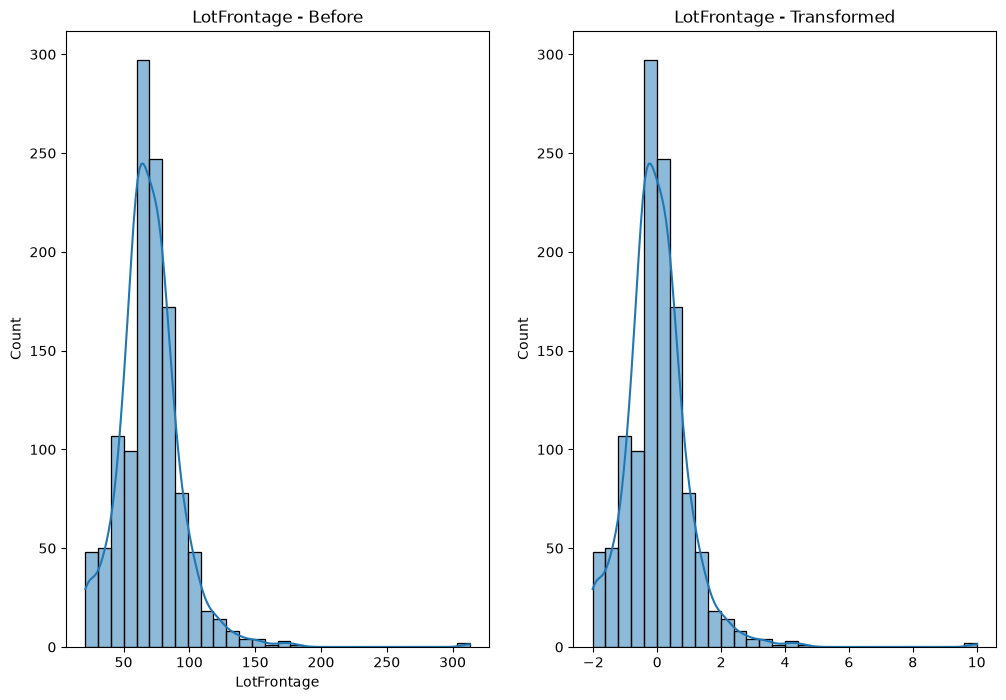

In [137]:
compare_distribution(dataset_3[column].dropna() , lot_scaled.flatten() , column)